# Low-Dimensional Subspace Optimization for Unlearnable Data

**Course:** CS F320 Foundations of Data Science, BITS Pilani Dubai
**Dataset:** CIFAR-10 | **Model:** ResNet-18 | **Framework:** PyTorch

## Question
Unlearnable Data (ULD) adds a tiny noise δ to training images so that models trained on them learn poorly. Existing methods search for δ over all 3072 pixel values of an image. **Do we need the full space, or is a small PCA subspace enough?** (δ = Uₖa, where we optimize only k values.)

## What this notebook does
1. Setup and data loading
2. ResNet-18 clean baseline
3. PCA basis of the training images
4. Full-space ULD noise (reference)
5. PCA-subspace ULD noise (our idea)
6. Experiments: vary k, compare PCA regions (top/middle/bottom), compare PCA vs random subspace
7. Results table and plots

## Rule for all experiments
Same epsilon (8/255), same epochs and same seed everywhere, so results are comparable.



---



# Setup

In [ ]:
import os, time, random, csv
import numpy as np
import torch, torchvision
import torch.nn as nn
import torch.nn.functional as F
from google.colab import drive

drive.mount('/content/drive')
PROJECT = '/content/drive/MyDrive/FDS_ULD_PCA'
os.makedirs(PROJECT, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
assert device == 'cuda', 'No GPU: Runtime > Change runtime type > pick a GPU'
print('GPU:', torch.cuda.get_device_name(0))

def set_seed(seed=0):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(0)

Mounted at /content/drive
GPU: NVIDIA L4


# Data (Cached copy on Drive if it exists)

In [ ]:
cache = f'{PROJECT}/cifar10_uint8.npz'
if os.path.exists(cache):
    d = np.load(cache)
    xtr, ytr, xte, yte = d['xtr'], d['ytr'], d['xte'], d['yte']
else:
    train_raw = torchvision.datasets.CIFAR10('./data', train=True,  download=True)
    test_raw  = torchvision.datasets.CIFAR10('./data', train=False, download=True)
    xtr, ytr = train_raw.data, np.array(train_raw.targets)
    xte, yte = test_raw.data,  np.array(test_raw.targets)
    np.savez(cache, xtr=xtr, ytr=ytr, xte=xte, yte=yte)

def to_tensor(arr):
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(255)

x_train, y_train = to_tensor(xtr).to(device), torch.tensor(ytr).to(device)
x_test,  y_test  = to_tensor(xte).to(device), torch.tensor(yte).to(device)
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Model

In [ ]:
MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def make_resnet18():
    r = torchvision.models.resnet18(num_classes=10)
    r.conv1 = nn.Conv2d(3, 64, 3, 1, 1, bias=False)
    r.maxpool = nn.Identity()
    return nn.Sequential(Normalize(MEAN, STD), r).to(device)

# Augmentation, Evaluate & Train

In [ ]:
def augment(x, pad=4):
    B = x.size(0)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad), mode='reflect')
    dy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ar = torch.arange(32, device=x.device)
    rows = (dy[:, None] + ar)[:, :, None]
    cols = (dx[:, None] + ar)[:, None, :]
    b = torch.arange(B, device=x.device)[:, None, None]
    out = xp.permute(0, 2, 3, 1)[b, rows, cols]
    return out.permute(0, 3, 1, 2).contiguous()

@torch.no_grad()
def evaluate(model, x, y, bs=1000):
    model.eval(); correct = 0
    for i in range(0, len(x), bs):
        with torch.autocast('cuda', dtype=torch.float16):
            correct += (model(x[i:i + bs]).argmax(1) == y[i:i + bs]).sum().item()
    return 100 * correct / len(x)

def train(model, x, y, epochs=15, lr=0.1, bs=128, test=None, verbose=True):
    n = len(x); steps = n // bs
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * steps)
    scaler = torch.amp.GradScaler('cuda')
    for ep in range(epochs):
        model.train(); t0 = time.time()
        perm = torch.randperm(n, device=x.device)
        for s in range(steps):
            idx = perm[s * bs:(s + 1) * bs]
            xb, yb = augment(x[idx]), y[idx]
            with torch.autocast('cuda', dtype=torch.float16):
                loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
        if verbose:
            msg = f'epoch {ep + 1}/{epochs} | loss {loss.item():.3f} | {time.time() - t0:.0f}s'
            if test is not None:
                msg += f' | test acc {evaluate(model, *test):.2f}%'
            print(msg)
    return model


# Results log

In [ ]:
RESULTS = f'{PROJECT}/results.csv'

def log_result(method, k, region, seed, acc, linf, secs):
    new = not os.path.exists(RESULTS)
    with open(RESULTS, 'a', newline='') as f:
        w = csv.writer(f)
        if new:
            w.writerow(['method', 'k', 'region', 'seed', 'clean_test_acc', 'linf', 'seconds'])
        w.writerow([method, k, region, seed, round(acc, 2), linf, round(secs, 1)])

if not os.path.exists(RESULTS):
    log_result('clean', '-', '-', 0, 92.52, 0, 336)
    log_result('full-space', 3072, '-', 0, 10.32, 0.03137, 56.3)
    log_result('pca', 100, 'top', 0, 29.46, 0.03137, 626.5)

clean_acc = 92.52

# PCA basis

In [ ]:
X = x_train.reshape(len(x_train), -1)
Xc = X - X.mean(0)
cov = Xc.T @ Xc / (len(Xc) - 1)
evals, evecs = torch.linalg.eigh(cov)
evals, evecs = evals.flip(0), evecs.flip(1)
del X, Xc, cov
torch.cuda.empty_cache()

def pca_basis(k, region='top'):
    D = evecs.shape[1]
    start = {'top': 0, 'bottom': D - k}.get(region, (D - k) // 2)
    return evecs[:, start:start + k]

def random_basis(k, seed=0):
    g = torch.Generator().manual_seed(seed)
    q, _ = torch.linalg.qr(torch.randn(3072, k, generator=g))
    return q.to(device)

# Noise Generator

In [ ]:
def make_classwise_noise(U=None, eps=8/255, max_iters=40, model_steps=50, noise_steps=20,
                         bs=256, lr_noise=0.1, target_acc=99.0, seed=0, verbose=True):
    set_seed(seed)
    full = U is None
    k = 3072 if full else U.shape[1]
    n = len(x_train)

    if full:
        p = ((torch.rand(10, 3072, device=device) * 2 - 1) * eps).requires_grad_(True)
    else:
        p = torch.randn(10, k, device=device).requires_grad_(True)
        opt_p = torch.optim.Adam([p], lr=lr_noise)

    def get_delta():
        if full:
            return p.view(10, 3, 32, 32)
        d = p @ U.T
        d = eps * d / (d.abs().amax(1, keepdim=True) + 1e-12)
        return d.view(10, 3, 32, 32)

    def batch():
        idx = torch.randint(0, n, (bs,), device=device)
        return x_train[idx], y_train[idx]

    surrogate = make_resnet18()
    opt_m = torch.optim.SGD(surrogate.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
    t0 = time.time()

    for it in range(1, max_iters + 1):
        surrogate.train()
        delta = get_delta().detach()
        for _ in range(model_steps):
            xb, yb = batch()
            loss = F.cross_entropy(surrogate((xb + delta[yb]).clamp(0, 1)), yb)
            opt_m.zero_grad(set_to_none=True); loss.backward(); opt_m.step()

        surrogate.eval()
        for q in surrogate.parameters():
            q.requires_grad_(False)
        for _ in range(noise_steps):
            xb, yb = batch()
            delta = get_delta()
            loss = F.cross_entropy(surrogate((xb + delta[yb]).clamp(0, 1)), yb)
            p.grad = None
            loss.backward()
            if full:
                with torch.no_grad():
                    p -= (eps / 10) * p.grad.sign()
                    p.clamp_(-eps, eps)
            else:
                opt_p.step()
        for q in surrogate.parameters():
            q.requires_grad_(True)

        with torch.no_grad():
            delta = get_delta()
            acc = evaluate(surrogate, (x_train[:5000] + delta[y_train[:5000]]).clamp(0, 1), y_train[:5000])
        if verbose:
            print(f'iter {it:>2} | surrogate acc on protected data {acc:.1f}% | loss {loss.item():.3f} | {time.time() - t0:.0f}s')
        if acc >= target_acc:
            break

    delta = get_delta().detach()
    info = dict(k=k, iters=it, surrogate_acc=round(acc, 1), seconds=round(time.time() - t0, 1),
                linf=round(delta.abs().max().item(), 5), l2=round(delta.flatten(1).norm(dim=1).mean().item(), 3))
    return delta, info

# Experiment Runners

In [ ]:
def run_uld_experiment(delta, info, method, k, region, seed=0, epochs=15):
    x_prot = (x_train + delta[y_train]).clamp(0, 1)
    set_seed(seed)
    m = make_resnet18()
    train(m, x_prot, y_train, epochs=epochs, test=(x_test, y_test))
    acc = evaluate(m, x_test, y_test)
    print(f'\n{method} k={k} {region}: clean test acc {acc:.2f}% '
          f'(baseline {clean_acc:.2f}%, drop {clean_acc - acc:.2f} points)')
    torch.save(delta.cpu(), f'{PROJECT}/delta_{method}_{k}_{region}_s{seed}.pt')
    log_result(method, k, region, seed, acc, info['linf'], info['seconds'])
    return acc

def run_subspace(kind, k, region='top', seed=0):
    U = pca_basis(k, region) if kind == 'pca' else random_basis(k, seed)
    delta, info = make_classwise_noise(U=U, seed=seed)
    print(info)
    return run_uld_experiment(delta, info, kind, k, region if kind == 'pca' else '-', seed)

print('setup done | train:', tuple(x_train.shape), '| PCA ready')

setup done | train: (50000, 3, 32, 32) | PCA ready


In [ ]:
# ===== QUEUE: resumable, safe to rerun after a disconnect =====
def already_done(kind, k, region, seed=0):
    if not os.path.exists(RESULTS):
        return False
    key = (kind, str(k), region if kind == 'pca' else '-', str(seed))
    with open(RESULTS) as f:
        return any((r['method'], r['k'], r['region'], r['seed']) == key for r in csv.DictReader(f))

queue = [('random', 100, 'top'), ('pca', 25, 'top'), ('pca', 500, 'top'), ('random', 25, 'top'),
         ('random', 500, 'top'), ('pca', 100, 'middle'), ('pca', 100, 'bottom'), ('pca', 3072, 'top')]

for kind, k, region in queue:
    if already_done(kind, k, region):
        print(f'skip {kind} k={k} {region} (already in results.csv)')
        continue
    print(f'\n=== {kind} k={k} {region} ===')
    run_subspace(kind, k, region)


=== random k=100 top ===
iter  1 | surrogate acc on protected data 28.6% | loss 1.983 | 8s
iter  2 | surrogate acc on protected data 36.6% | loss 1.731 | 14s
iter  3 | surrogate acc on protected data 42.9% | loss 1.690 | 20s
iter  4 | surrogate acc on protected data 48.3% | loss 1.295 | 25s
iter  5 | surrogate acc on protected data 80.4% | loss 0.603 | 31s
iter  6 | surrogate acc on protected data 99.8% | loss 0.045 | 37s
{'k': 100, 'iters': 6, 'surrogate_acc': 99.8, 'seconds': 36.9, 'linf': 0.03137, 'l2': 0.598}
epoch 1/15 | loss 1.119 | 9s | test acc 56.24%
epoch 2/15 | loss 0.993 | 9s | test acc 63.82%
epoch 3/15 | loss 0.830 | 9s | test acc 71.74%
epoch 4/15 | loss 0.615 | 9s | test acc 75.77%
epoch 5/15 | loss 0.536 | 9s | test acc 79.12%
epoch 6/15 | loss 0.520 | 9s | test acc 79.24%
epoch 7/15 | loss 0.304 | 9s | test acc 74.78%
epoch 8/15 | loss 0.331 | 9s | test acc 78.24%
epoch 9/15 | loss 0.181 | 9s | test acc 36.45%
epoch 10/15 | loss 0.005 | 9s | test acc 18.61%
epoch 11/

In [ ]:
# ===== QUEUE 2: extra seeds + smaller k (safe to rerun after a disconnect) =====
def already_done(kind, k, region, seed=0):
    """True if this exact run is already saved in results.csv."""
    if not os.path.exists(RESULTS):
        return False
    key = (kind, str(k), region if kind == 'pca' else '-', str(seed))
    with open(RESULTS) as f:
        return any((r['method'], r['k'], r['region'], r['seed']) == key for r in csv.DictReader(f))

configs = [('random', 100, 'top'), ('pca', 25, 'top'), ('pca', 100, 'top'), ('pca', 500, 'top'),
           ('random', 25, 'top'), ('random', 500, 'top'), ('pca', 100, 'middle'),
           ('pca', 100, 'bottom'), ('pca', 3072, 'top')]

extras = [('pca', 25, 'bottom'), ('pca', 500, 'bottom'), ('pca', 10, 'bottom'),
          ('random', 10, 'top'), ('random', 5, 'top')]

jobs = [(c, 0) for c in extras] + [(c, s) for s in (1, 2) for c in configs]
print(len(jobs), 'jobs in the queue')

for (kind, k, region), seed in jobs:
    if already_done(kind, k, region, seed):
        print(f'skip {kind} k={k} {region} seed={seed} (already done)')
        continue
    print(f'\n=== {kind} k={k} {region} seed={seed} ===')
    run_subspace(kind, k, region, seed)

23 jobs in the queue

=== pca k=25 bottom seed=0 ===
iter  1 | surrogate acc on protected data 26.1% | loss 2.322 | 6s
iter  2 | surrogate acc on protected data 39.2% | loss 1.723 | 11s
iter  3 | surrogate acc on protected data 97.0% | loss 0.075 | 17s
iter  4 | surrogate acc on protected data 100.0% | loss 0.000 | 23s
{'k': 25, 'iters': 4, 'surrogate_acc': 100.0, 'seconds': 22.9, 'linf': 0.03137, 'l2': 0.448}
epoch 1/15 | loss 0.569 | 9s | test acc 27.58%
epoch 2/15 | loss 0.001 | 9s | test acc 15.27%
epoch 3/15 | loss 0.001 | 9s | test acc 10.00%
epoch 4/15 | loss 0.000 | 9s | test acc 13.30%
epoch 5/15 | loss 0.001 | 9s | test acc 11.31%
epoch 6/15 | loss 0.000 | 9s | test acc 10.12%
epoch 7/15 | loss 0.001 | 9s | test acc 9.96%
epoch 8/15 | loss 0.001 | 9s | test acc 10.00%
epoch 9/15 | loss 0.001 | 9s | test acc 10.00%
epoch 10/15 | loss 0.001 | 9s | test acc 10.00%
epoch 11/15 | loss 0.001 | 9s | test acc 10.00%
epoch 12/15 | loss 0.001 | 9s | test acc 10.00%
epoch 13/15 | loss 0

In [ ]:
# ===== long run: does PCA top-25 just need more iterations? =====
U = pca_basis(25, 'top')                              # the 25 highest-variance directions
delta, info = make_classwise_noise(U=U, max_iters=120)   # allow up to 120 rounds instead of 40
print(info)
run_uld_experiment(delta, info, 'pca-long', 25, 'top')   # logged under a different name, 'pca-long'

iter  1 | surrogate acc on protected data 35.1% | loss 1.966 | 6s
iter  2 | surrogate acc on protected data 50.4% | loss 1.315 | 11s
iter  3 | surrogate acc on protected data 58.4% | loss 1.145 | 17s
iter  4 | surrogate acc on protected data 68.2% | loss 0.803 | 23s
iter  5 | surrogate acc on protected data 71.3% | loss 0.779 | 29s
iter  6 | surrogate acc on protected data 76.3% | loss 0.840 | 35s
iter  7 | surrogate acc on protected data 78.3% | loss 0.619 | 40s
iter  8 | surrogate acc on protected data 82.2% | loss 0.545 | 46s
iter  9 | surrogate acc on protected data 85.0% | loss 0.579 | 52s
iter 10 | surrogate acc on protected data 85.6% | loss 0.447 | 58s
iter 11 | surrogate acc on protected data 87.1% | loss 0.352 | 64s
iter 12 | surrogate acc on protected data 88.5% | loss 0.280 | 70s
iter 13 | surrogate acc on protected data 88.0% | loss 0.449 | 76s
iter 14 | surrogate acc on protected data 87.0% | loss 0.436 | 81s
iter 15 | surrogate acc on protected data 89.0% | loss 0.352 | 

65.04

In [ ]:
# ===== QUEUE 3: more seeds on the key configs (needs the SETUP cell run first) =====
def already_done(kind, k, region, seed=0):
    """True if this exact run is already saved in results.csv."""
    if not os.path.exists(RESULTS):
        return False
    key = (kind, str(k), region if kind == 'pca' else '-', str(seed))
    with open(RESULTS) as f:
        return any((r['method'], r['k'], r['region'], r['seed']) == key for r in csv.DictReader(f))

key_configs = [('pca', 3072, 'top'), ('random', 500, 'top'), ('random', 100, 'top'),
               ('pca', 100, 'top'), ('pca', 100, 'bottom')]

for seed in (3, 4):
    for kind, k, region in key_configs:
        if already_done(kind, k, region, seed):
            print(f'skip {kind} k={k} {region} seed={seed}')
            continue
        print(f'\n=== {kind} k={k} {region} seed={seed} ===')
        run_subspace(kind, k, region, seed)


=== pca k=3072 top seed=3 ===
iter  1 | surrogate acc on protected data 29.2% | loss 1.864 | 8s
iter  2 | surrogate acc on protected data 44.3% | loss 1.538 | 14s
iter  3 | surrogate acc on protected data 89.5% | loss 0.355 | 20s
iter  4 | surrogate acc on protected data 99.9% | loss 0.002 | 26s
{'k': 3072, 'iters': 4, 'surrogate_acc': 99.9, 'seconds': 25.6, 'linf': 0.03137, 'l2': 0.449}
epoch 1/15 | loss 1.080 | 9s | test acc 52.36%
epoch 2/15 | loss 0.968 | 9s | test acc 66.56%
epoch 3/15 | loss 0.619 | 9s | test acc 71.86%
epoch 4/15 | loss 0.482 | 9s | test acc 78.62%
epoch 5/15 | loss 0.386 | 9s | test acc 60.63%
epoch 6/15 | loss 0.262 | 9s | test acc 44.87%
epoch 7/15 | loss 0.237 | 9s | test acc 45.40%
epoch 8/15 | loss 0.161 | 9s | test acc 33.72%
epoch 9/15 | loss 0.077 | 9s | test acc 15.55%
epoch 10/15 | loss 0.004 | 9s | test acc 20.91%
epoch 11/15 | loss 0.024 | 9s | test acc 17.42%
epoch 12/15 | loss 0.001 | 9s | test acc 15.61%
epoch 13/15 | loss 0.001 | 9s | test acc 

In [ ]:
# ===== QUEUE 4: lower k for bottom directions + missing seeds =====
def already_done(kind, k, region, seed=0):
    if not os.path.exists(RESULTS):
        return False
    key = (kind, str(k), region if kind == 'pca' else '-', str(seed))
    with open(RESULTS) as f:
        return any((r['method'], r['k'], r['region'], r['seed']) == key for r in csv.DictReader(f))

jobs = []
for seed in (0, 1, 2):                        # find where bottom directions break
    for k in (2, 3, 5):
        jobs.append((('pca', k, 'bottom'), seed))
for seed in (1, 2):                           # more seeds for the single-seed rows
    for k in (10, 25):
        jobs.append((('pca', k, 'bottom'), seed))
    for k in (5, 10):
        jobs.append((('random', k, 'top'), seed))
for seed in (3, 4):                           # middle: 3 -> 5 seeds
    jobs.append((('pca', 100, 'middle'), seed))

print(len(jobs), 'jobs in the queue')
for (kind, k, region), seed in jobs:
    if already_done(kind, k, region, seed):
        print(f'skip {kind} k={k} {region} seed={seed}'); continue
    print(f'\n=== {kind} k={k} {region} seed={seed} ===')
    run_subspace(kind, k, region, seed)

19 jobs in the queue

=== pca k=2 bottom seed=0 ===
iter  1 | surrogate acc on protected data 27.8% | loss 2.546 | 8s
iter  2 | surrogate acc on protected data 41.2% | loss 1.635 | 14s
iter  3 | surrogate acc on protected data 75.9% | loss 0.748 | 20s
iter  4 | surrogate acc on protected data 99.0% | loss 0.105 | 25s
iter  5 | surrogate acc on protected data 99.9% | loss 0.019 | 31s
{'k': 2, 'iters': 5, 'surrogate_acc': 99.9, 'seconds': 31.0, 'linf': 0.03137, 'l2': 0.356}
epoch 1/15 | loss 1.019 | 9s | test acc 58.45%
epoch 2/15 | loss 1.013 | 9s | test acc 57.90%
epoch 3/15 | loss 0.790 | 9s | test acc 72.49%
epoch 4/15 | loss 0.512 | 9s | test acc 77.41%
epoch 5/15 | loss 0.503 | 9s | test acc 80.11%
epoch 6/15 | loss 0.461 | 9s | test acc 79.76%
epoch 7/15 | loss 0.279 | 9s | test acc 74.79%
epoch 8/15 | loss 0.437 | 9s | test acc 83.98%
epoch 9/15 | loss 0.317 | 9s | test acc 85.59%
epoch 10/15 | loss 0.351 | 9s | test acc 85.95%
epoch 11/15 | loss 0.310 | 9s | test acc 86.65%
epoc

In [ ]:
# ===== QUEUE 5: extra seeds to firm up the bottom-PCA claims =====
# Why: k=500 bottom had only 1 run (the point where bottom beats random),
#      and k=5/10/25 bottom had only 3 seeds (the "reliable from k=25" threshold).
# 8 jobs, ~25 min. Safe to rerun after a disconnect: finished runs are skipped.
import os, csv

def already_done(kind, k, region, seed=0):
    if not os.path.exists(RESULTS):
        return False
    key = (kind, str(k), region if kind == 'pca' else '-', str(seed))
    with open(RESULTS) as f:
        return any((r['method'], r['k'], r['region'], r['seed']) == key for r in csv.DictReader(f))

jobs = [(('pca', k, 'bottom'), s) for s in (3, 4) for k in (5, 10, 25)]   # seeds 3-4 at k=5, 10, 25
jobs += [(('pca', 500, 'bottom'), s) for s in (1, 2)]                     # seeds 1-2 at k=500

print(len(jobs), 'jobs in the queue')
for (kind, k, region), seed in jobs:
    if already_done(kind, k, region, seed):
        print(f'skip {kind} k={k} {region} seed={seed}'); continue
    print(f'\n=== {kind} k={k} {region} seed={seed} ===')
    run_subspace(kind, k, region, seed)

8 jobs in the queue

=== pca k=5 bottom seed=3 ===
iter  1 | surrogate acc on protected data 26.6% | loss 2.021 | 6s
iter  2 | surrogate acc on protected data 73.4% | loss 0.723 | 11s
iter  3 | surrogate acc on protected data 100.0% | loss 0.001 | 17s
{'k': 5, 'iters': 3, 'surrogate_acc': 100.0, 'seconds': 17.2, 'linf': 0.03137, 'l2': 0.371}
epoch 1/15 | loss 1.144 | 9s | test acc 55.73%
epoch 2/15 | loss 0.893 | 9s | test acc 68.58%
epoch 3/15 | loss 0.618 | 9s | test acc 73.75%
epoch 4/15 | loss 0.593 | 9s | test acc 75.40%
epoch 5/15 | loss 0.388 | 9s | test acc 80.06%
epoch 6/15 | loss 0.324 | 9s | test acc 77.97%
epoch 7/15 | loss 0.423 | 9s | test acc 83.09%
epoch 8/15 | loss 0.418 | 9s | test acc 84.55%
epoch 9/15 | loss 0.409 | 9s | test acc 84.85%
epoch 10/15 | loss 0.266 | 9s | test acc 86.84%
epoch 11/15 | loss 0.304 | 9s | test acc 85.60%
epoch 12/15 | loss 0.221 | 9s | test acc 82.57%
epoch 13/15 | loss 0.011 | 9s | test acc 11.03%
epoch 14/15 | loss 0.002 | 9s | test acc 

method region    k  runs  mean  std  median  lowest  highest  runs_above_50
   pca bottom    2     3  68.2 42.1    92.5    19.7     92.6              2
   pca bottom    3     3  64.9 47.5    92.2    10.0     92.4              2
   pca bottom    5     5  42.9 45.0    10.2    10.0     92.7              2
   pca bottom   10     5  43.0 45.3    10.0    10.0     92.6              2
   pca bottom   25     5  26.5 36.9    10.0    10.0     92.5              1
   pca bottom  100     5  10.0  0.0    10.0    10.0     10.0              0
   pca bottom  500     3  10.0  0.0    10.0    10.0     10.0              0
   pca middle  100     5  24.9 10.1    30.1    10.7     34.4              0
   pca    top   25     3  63.6  0.2    63.6    63.4     63.8              3
   pca    top  100     5  30.7  4.5    29.5    26.0     37.9              0
   pca    top  500     3  26.4  4.7    23.9    23.6     31.9              0
   pca    top 3072     5  28.7 35.1    14.4    10.4     91.4              1
random      

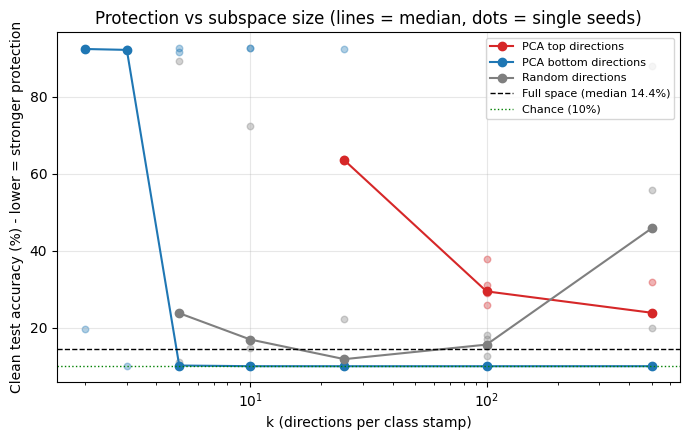

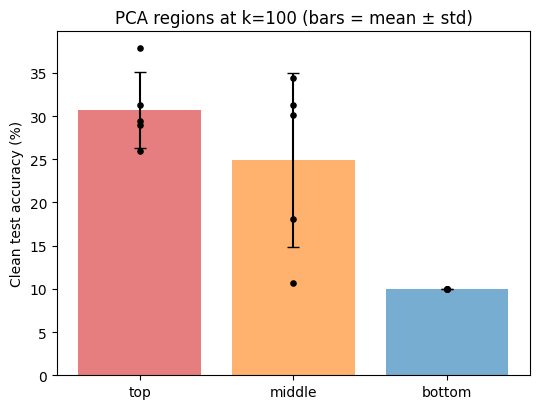

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(RESULTS)
df = df[df.method.isin(['pca', 'random'])].copy()      # leaves out 'pca-long' and reference rows
df['k'] = df['k'].astype(int)

summary = (df.groupby(['method', 'region', 'k']).clean_test_acc
             .agg(runs='count', mean='mean', std='std', median='median', lowest='min', highest='max')
             .round(1).reset_index())
fails = (df.assign(failed=df.clean_test_acc > 50)
           .groupby(['method', 'region', 'k']).failed.sum().reset_index(name='runs_above_50'))
summary = summary.merge(fails, on=['method', 'region', 'k'])
print(summary.to_string(index=False))
summary.to_csv(f'{PROJECT}/summary_table.csv', index=False)

# Plot 1: accuracy vs k
fig, ax = plt.subplots(figsize=(7, 4.5))
series = [('pca', 'top', 'PCA top directions', 'tab:red'),
          ('pca', 'bottom', 'PCA bottom directions', 'tab:blue'),
          ('random', '-', 'Random directions', 'tab:gray')]
for method, region, label, colour in series:
    d = df[(df.method == method) & (df.region == region) & (df.k < 3072)]
    if d.empty: continue
    med = d.groupby('k').clean_test_acc.median()
    ax.scatter(d.k, d.clean_test_acc, color=colour, alpha=0.35, s=22)
    ax.plot(med.index, med.values, marker='o', color=colour, label=label)
full = df[(df.method == 'pca') & (df.k == 3072)].clean_test_acc.median()
ax.axhline(full, ls='--', color='k', lw=1, label=f'Full space (median {full:.1f}%)')
ax.axhline(10, ls=':', color='green', lw=1, label='Chance (10%)')
ax.set_xscale('log'); ax.set_xlabel('k (directions per class stamp)')
ax.set_ylabel('Clean test accuracy (%) - lower = stronger protection')
ax.set_title('Protection vs subspace size (lines = median, dots = single seeds)')
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(f'{PROJECT}/plot_acc_vs_k.png', dpi=200); plt.show()

# Plot 2: top / middle / bottom at k=100
fig, ax = plt.subplots(figsize=(5.5, 4.2))
cols = ['tab:red', 'tab:orange', 'tab:blue']
for i, r in enumerate(['top', 'middle', 'bottom']):
    d = df[(df.method == 'pca') & (df.k == 100) & (df.region == r)].clean_test_acc
    ax.bar(i, d.mean(), color=cols[i], alpha=0.6, yerr=d.std() if len(d) > 1 else 0, capsize=4)
    ax.scatter([i] * len(d), d, color='k', s=14, zorder=3)
ax.set_xticks(range(3)); ax.set_xticklabels(['top', 'middle', 'bottom'])
ax.set_ylabel('Clean test accuracy (%)'); ax.set_title('PCA regions at k=100 (bars = mean ± std)')
fig.tight_layout(); fig.savefig(f'{PROJECT}/plot_regions_k100.png', dpi=200); plt.show()

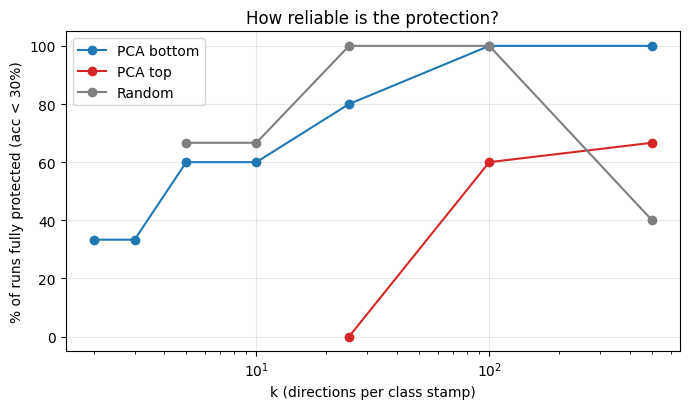

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

d = pd.read_csv(RESULTS)
d = d[d.method.isin(['pca', 'random'])].copy()
d['k'] = d['k'].astype(int)
d['protected'] = d.clean_test_acc < 30

fig, ax = plt.subplots(figsize=(7, 4.2))
for method, region, label, colour in [('pca', 'bottom', 'PCA bottom', 'tab:blue'),
                                      ('pca', 'top', 'PCA top', 'tab:red'),
                                      ('random', '-', 'Random', 'tab:gray')]:
    s = d[(d.method == method) & (d.region == region) & (d.k < 3072)]
    rate = s.groupby('k').protected.mean() * 100
    ax.plot(rate.index, rate.values, marker='o', color=colour, label=label)
ax.set_xscale('log'); ax.set_ylim(-5, 105)
ax.set_xlabel('k (directions per class stamp)'); ax.set_ylabel('% of runs fully protected (acc < 30%)')
ax.set_title('How reliable is the protection?'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f'{PROJECT}/plot_success_rate.png', dpi=200); plt.show()

## Extra runs (added after the main queues)
**Queue 6** adds seeds 1-4 of the standard full-space baseline. The **demo models** cell trains the two models used in the demo notebook's live check.

In [ ]:
# ===== QUEUE 6: full-space sign-PGD baseline, seeds 1-4 (seed 0 already done) =====
import pandas as pd

def already_done(method, k, region, seed):
    if not os.path.exists(RESULTS): return False
    r = pd.read_csv(RESULTS, dtype=str)
    return ((r.method == method) & (r.k == str(k)) & (r.region == region) & (r.seed == str(seed))).any()

for seed in [1, 2, 3, 4]:
    if already_done('full-space', 3072, '-', seed):
        print(f'seed {seed}: already in results.csv, skipping'); continue
    print(f'\n===== full-space sign-PGD, seed {seed} =====')
    delta, info = make_classwise_noise(U=None, seed=seed)     # U=None -> standard full-space sign-PGD
    print(info)
    run_uld_experiment(delta, info, 'full-space', 3072, '-', seed)

r = pd.read_csv(RESULTS)
fs = r[r.method == 'full-space']
print('\nFull-space sign-PGD, all seeds:')
print(fs[['seed', 'clean_test_acc', 'seconds']].to_string(index=False))
print(f'mean {fs.clean_test_acc.mean():.2f} | median {fs.clean_test_acc.median():.2f} | protected (<30%): {(fs.clean_test_acc < 30).sum()} of {len(fs)}')


In [ ]:
# DEMO MODELS: train one clean and one protected model, save both to Drive (run once, ~5 min)
delta = torch.load(f'{PROJECT}/delta_pca_100_bottom_s0.pt', map_location=device)
x_prot = (x_train + delta[y_train]).clamp(0, 1)          # same protected set as the results

# 1) model trained on normal data
set_seed(0)
clean_model = make_resnet18()
train(clean_model, x_train, y_train, epochs=15, test=(x_test, y_test))
torch.save(clean_model.state_dict(), f'{PROJECT}/demo_model_clean.pt')

# 2) model trained on protected data (PCA bottom, k=100, seed 0)
set_seed(0)
prot_model = make_resnet18()
train(prot_model, x_prot, y_train, epochs=15, test=(x_test, y_test))
torch.save(prot_model.state_dict(), f'{PROJECT}/demo_model_protected.pt')

print('\nclean model      | clean test acc:', round(evaluate(clean_model, x_test, y_test), 2))
print('protected model  | clean test acc:', round(evaluate(prot_model, x_test, y_test), 2))
print('protected model  | stamped train acc (first 10,000):', round(evaluate(prot_model, x_prot[:10000], y_train[:10000]), 2))
